<a href="https://colab.research.google.com/github/madeeha-noor/BERT-Fine-Tuning-Reproduction/blob/main/02_DataLoader_Embeddings.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install transformers datasets

import random
import numpy as np
import torch
from collections import Counter
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from datasets import load_dataset
from transformers import AutoTokenizer

In [ ]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
  torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| Device:", device)

PyTorch: 2.14.1+cpu | Device: cpu


In [ ]:
raw = load_dataset("nyu-mll/glue", "sst2")
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

print(raw)
print("PAD id:", tokenizer.pad_token_id, "| CLS id:", tokenizer.cls_token_id, "| SEP id:", tokenizer.sep_token_id)

README.md:   0%|          | 0.00/35.3k [00:00<?, ?B/s]

sst2/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.11MB            

sst2/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sst2/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 72.8kB            

sst2/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sst2/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  148kB            

... (5 outputs left out)

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

DatasetDict({
    train: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 67349
    })
    validation: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 872
    })
    test: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 1821
    })
})
PAD id: 0 | CLS id: 101 | SEP id: 102


## 1. Own Dataset Class
- 'Sentiment Dataset' pre-tokenises every sentence once (no padding) and stores 'input_ids', 'token_type_ids', and the label
- '__getitem__(i)' returns one example; padding is done later, per batch by 'collate_fn'
- Only the labelled splits (train and validation) are used: the GLUE test labels are hidden (-1)

In [ ]:
MAX_LEN = 128

class SentimentDataset(Dataset):
  def __init__(self, hf_split, tokenizer, text_col="sentence", label_col="label", max_length=MAX_LEN):
    texts = list(hf_split[text_col])
    self.labels = list(hf_split[label_col])
    # Tokenise everything once. No padding here; truncate only if longer than max_lenght
    enc = tokenizer(texts, truncation=True, max_length=max_length)
    self.input_ids = enc["input_ids"]
    self.token_type_ids = enc["token_type_ids"]

  def __len__(self):
    return len(self.labels)

  def __getitem__(self, idx):
    return {
        "input_ids": self.input_ids[idx],
        "token_type_ids": self.token_type_ids[idx],
        "label": self.labels[idx],
    }

train_ds = SentimentDataset(raw["train"], tokenizer)
val_ds = SentimentDataset(raw["validation"], tokenizer)

print("Train size:", len(train_ds), "| Validation size:", len(val_ds))
print("Example 0:", train_ds[0])

Train size: 67349 | Validation size: 872
Example 0: {'input_ids': [101, 5342, 2047, 3595, 8496, 2013, 1996, 18643, 3197, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'label': 0}


In [ ]:
PAD_ID = tokenizer.pad_token_id

def collate_fn(batch):
  B = len(batch)
  max_len = max(len(x["input_ids"]) for x in batch)

  input_ids      = torch.full((B, max_len), PAD_ID, dtype=torch.long)
  token_type_ids = torch.zeros((B, max_len), dtype=torch.long)
  attention_mask = torch.zeros((B, max_len), dtype=torch.long)

  for i, x in enumerate(batch):
    n = len(x["input_ids"])
    input_ids[i, :n]      = torch.tensor(x["input_ids"], dtype=torch.long)
    token_type_ids[i, :n] = torch.tensor(x["token_type_ids"], dtype=torch.long)
    attention_mask[i, :n] = 1

  labels = torch.tensor([x["label"] for x in batch], dtype=torch.long)

  return {
      "input_ids": input_ids,
      "token_type_ids": token_type_ids,
      "attention_mask": attention_mask,
      "labels": labels,
  }

In [ ]:
BATCH_SIZE = 32

g = torch.Generator()
g.manual_seed(SEED)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          collate_fn=collate_fn, generator=g)
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False,
                        collate_fn=collate_fn)

print("Train batches:", len(train_loader), "| Validation batches:", len(val_loader))

Train batches: 2105 | Validation batches: 14


## 2. Checking one batch
- Required checks: shapes, dtypes, labels, padding behavious
- Note on normalisation: text has no pixel normalisation. The equivalent rule is that any statistic (vocabulary, length cut-offs) is computed on the **training split only**

In [ ]:
batch = next(iter(train_loader))

for k, v in batch.items():
  print(f"{k:16s} shape={tuple(v.shape)} dtype={v.dtype}")

B, L = batch["input_ids"].shape
assert B == BATCH_SIZE
assert L <= MAX_LEN
assert batch["attention_mask"].shape == (B, L)
assert batch["token_type_ids"].shape == (B, L)
assert batch["labels"].shape ==(B,)
assert batch["input_ids"].dtype == torch.long
assert batch["labels"].dtype == torch.long

#padding positions must be exactly where the mask is 0
assert torch.equal(batch["attention_mask"] == 0, batch["input_ids"] == PAD_ID)
#every sentence must start with [CLS]
assert (batch["input_ids"][:, 0] == tokenizer.cls_token_id).all()

print(f"\nAll checks passed. This batch padded to {L} tokens, not {MAX_LEN} (dynamic padding).")

input_ids        shape=(32, 33) dtype=torch.int64
token_type_ids   shape=(32, 33) dtype=torch.int64
attention_mask   shape=(32, 33) dtype=torch.int64
labels           shape=(32,) dtype=torch.int64

All checks passed. This batch padded to 33 tokens, not 128 (dynamic padding).


In [ ]:
label_names = {0: "Negative", 1: "Positive"}

print(f"{'label':10s} | sentence")
print("-" * 70)
for i in range(8):
  text = tokenizer.decode(batch["input_ids"][i], skip_special_tokens=True)
  print(f"{label_names[batch['labels'][i].item()]:10s} | {text}")

label      | sentence
----------------------------------------------------------------------
Positive   | tends to remind one of a really solid woody allen film, with its excellent use of new york locales and sharp writing
Positive   | are side stories aplenty
Positive   | onto the end credits
Positive   | this amiable picture talks tough, but it ' s all bluster - - in the end it ' s as sweet as greenfingers
Negative   | ' s kinda dumb
Positive   | inspiring and
Positive   | strong filmmaking requires a clear sense of purpose
Positive   | humorous and heartfelt,


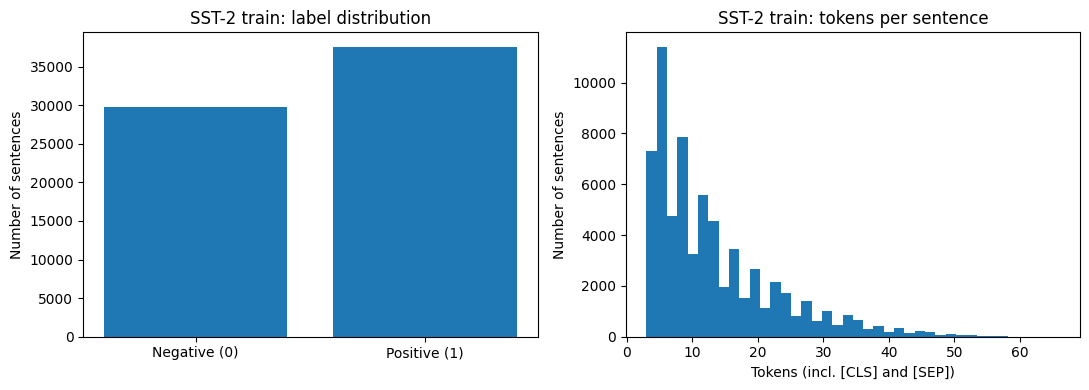

Labels: {0: 29780, 1: 37569}
Token length: mean = 13.3 | max = 66 | 95th percentile = 33


In [ ]:
train_lengths = [len(x) for x in train_ds.input_ids]
label_counts = Counter(train_ds.labels)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].bar(["Negative (0)", "Positive (1)"], [label_counts[0], label_counts[1]])
ax[0].set_title("SST-2 train: label distribution")
ax[0].set_ylabel("Number of sentences")

ax[1].hist(train_lengths, bins=40)
ax[1].set_title("SST-2 train: tokens per sentence")
ax[1].set_xlabel("Tokens (incl. [CLS] and [SEP])")
ax[1].set_ylabel("Number of sentences")

plt.tight_layout()
plt.show()

print("Labels:", dict(label_counts))
print("Token length: mean =", round(np.mean(train_lengths), 1),
      "| max =", max(train_lengths), "| 95th percentile =", int(np.percentile(train_lengths, 95)))

**Findings (Data Lead).**
- SST-2 train has 67,349 sentences (29,780 negative, 37,569 positive); validation has 872 (428 / 444)
- Sentences are short, so padding each to 128 would waste compute; 'collate_fn' pads dynamically to the longest sentence in each batch
- 'attention_mask' is 0 exactly at '[PAD]' possitions (asserted)
- The GLUE test split has hidden labels (-1), so the reproduction is evaluated on the validation set

## 3. Own BERT embeddings layer
- 'MyBertEmbeddings' = word + position + segment embeddings, summed, then LayerNorm and dropout
- Check: load the pretrained weights into it and confirm its output equals Hugging Face's 'BertEmbeddings'on the same batch.
- Then counts its parameter by hand

In [ ]:
import torch.nn as nn
from transformers import BertModel

hf_model = BertModel.from_pretrained("bert-base-uncased").to(device)
hf_emb = hf_model.embeddings

cfg = hf_model.config
print("vocab_size:", cfg.vocab_size, "| hiddeen:", cfg.hidden_size,
      "| max_positions:", cfg.max_position_embeddings, "| segments:", cfg.type_vocab_size)
print("layer_orm_eps:", cfg.layer_norm_eps, "| dropout:", cfg.hidden_dropout_prob)

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


vocab_size: 30522 | hiddeen: 768 | max_positions: 512 | segments: 2
layer_orm_eps: 1e-12 | dropout: 0.1


In [ ]:
class MyBertEmbeddings(nn.Module):
  def __init__(self, vocab_size=30522, hidden=768, max_pos=512,
               type_vocab=2, dropout=0.1, eps=1e-12):
    super().__init__()
    self.word_embeddings       = nn.Embedding(vocab_size, hidden, padding_idx=0)
    self.position_embeddings   = nn.Embedding(max_pos, hidden)
    self.token_type_embeddings = nn.Embedding(type_vocab, hidden)
    self.LayerNorm = nn.LayerNorm(hidden, eps=eps)
    self.dropout   = nn.Dropout(dropout)

  def forward(self, input_ids, token_type_ids=None):
    B, L = input_ids.shape
    if token_type_ids is None:
      token_type_ids = torch.zeros_like(input_ids)
    position_ids = torch.arange(L, device=input_ids.device).unsqueeze(0)

    x = (self.word_embeddings(input_ids)
         + self.position_embeddings(position_ids)
         + self.token_type_embeddings(token_type_ids))
    x = self.LayerNorm(x)
    x = self.dropout(x)
    return x

In [ ]:
my_emb = MyBertEmbeddings().to(device)

hf_state = {k: v for k, v in hf_emb.state_dict().items() if "position_ids" not in k}
print(my_emb.load_state_dict(hf_state))

my_emb.eval()
hf_emb.eval()

ids = batch["input_ids"].to(device)
segs = batch["token_type_ids"].to(device)

with torch.no_grad():
  mine = my_emb(ids, segs)
  ref = hf_emb(input_ids=ids, token_type_ids=segs)

print("Mine:", tuple(mine.shape), "| HF:", tuple(ref.shape))
print("Max absolute difference:", (mine - ref).abs().max().item())

assert mine.shape == ref.shape == (ids.shape[0], ids.shape[1], 768)
assert torch.allclose(mine, ref, atol=1e-6)
print("Embeddings match Hugging Face!")

<All keys matched successfully>
Mine: (32, 33, 768) | HF: (32, 33, 768)
Max absolute difference: 9.5367431640625e-07
Embeddings match Hugging Face!


In [ ]:
with torch.no_grad():
  w = my_emb.word_embeddings(ids)
  p = my_emb.position_embeddings(torch.arange(ids.shape[1], device=device).unsqueeze(0))
  t = my_emb.token_type_embeddings(segs)
  s = w + p + t
  n = my_emb.LayerNorm(s)

print("input_ids             :", tuple(ids.shape))
print("word embeddings       :", tuple(w.shape))
print("position embeddings   :", tuple(p.shape), "(broadcast over the batch)")
print("segment embeddings    :", tuple(t.shape))
print("sum                   :", tuple(s.shape))
print("after LayerNorm       :", tuple(n.shape))
print("after dropout (output):", tuple(mine.shape))

input_ids             : (32, 33)
word embeddings       : (32, 33, 768)
position embeddings   : (1, 33, 768) (broadcast over the batch)
segment embeddings    : (32, 33, 768)
sum                   : (32, 33, 768)
after LayerNorm       : (32, 33, 768)
after dropout (output): (32, 33, 768)


In [ ]:
V, H, P, T = 30522, 768, 512, 2

word_params = V * H
pos_params  = P * H
type_params = T * H
ln_params   = H + H

hand_total = word_params + pos_params + type_params + ln_params

print("Word embeddings    :", f"{word_params:,}")
print("Position embeddings:", f"{pos_params:,}")
print("Segment embeddings :", f"{type_params:,}")
print("LayerNorm          :", f"{ln_params:,}")
print("Hand total         :", f"{hand_total:,}")

mine_count = sum(p.numel() for p in my_emb.parameters())
hf_count   = sum(p.numel() for p in hf_emb.parameters())

print("PyTorch (mine):", f"{mine_count:,}")
print("PyTorch (HF):", f"{hf_count:,}")

assert hand_total == mine_count == hf_count
print("Parameters count verified!")

Word embeddings    : 23,440,896
Position embeddings: 393,216
Segment embeddings : 1,536
LayerNorm          : 1,536
Hand total         : 23,837,184
PyTorch (mine): 23,837,184
PyTorch (HF): 23,837,184
Parameters count verified!


In [ ]:
encoder_params = 12 * 7_087_872
pooler_params = 768 * 768 + 768
total_hand = hand_total + encoder_params + pooler_params
total_hf = sum(p.numel() for p in hf_model.parameters())

print("Embeddings:", f"{hand_total:,}")
print("12 encoder layers:", f"{encoder_params:,}")
print("Pooler:", f"{pooler_params:,}")
print("Total (hand):", f"{total_hand:,}")
print("Total (HF BertModel):", f"{total_hf:,}")

assert total_hand == total_hf
print("Whole-model count verified!  (+ classification head 768*2+2 = 1538 -> 109,483,778)")

Embeddings: 23,837,184
12 encoder layers: 85,054,464
Pooler: 590,592
Total (hand): 109,482,240
Total (HF BertModel): 109,482,240
Whole-model count verified!  (+ classification head 768*2+2 = 1538 -> 109,483,778)


**Findings (embeddings).**
- `MyBertEmbeddings` = word (30,522×768) + position (512×768) + segment (2×768) embeddings, summed, then LayerNorm(768) and dropout(0.1).
- Shape trace: `[B, L]` → `[B, L, 768]`; position embeddings are `[1, L, 768]` and broadcast over the batch.
- With pretrained weights loaded and dropout off, the output matches Hugging Face `BertEmbeddings` (max difference below 1e-6).
- Hand count: 23,440,896 + 393,216 + 1,536 + 1,536 = 23,837,184 parameters, which matches PyTorch.
- Whole model: 23,837,184 (embeddings) + 85,054,464 (12 encoder layers) + 590,592 (pooler) = 109,482,240.